### Choose the dataset 
### Preprocess the dataset 
### Specify the model 
### Specify the evaluation metrics
### Run experiments and log with mlflow


In [4]:
import torch
import torchaudio

def add_white_noise(waveform:torch.tensor, snr_db=15):
    noise = torchaudio.randn_like(waveform)
    snr = waveform.new_full(waveform.shape[:-1], float(snr_db))
    return torchaudio.functional.add_noise(waveform, noise, snr)


In [ ]:
from collections import Counter
from pathlib import Path
from datasets import load_dataset, Audio

dataset = load_dataset(
    "openslr/librispeech_asr",
    "clean",
    split="test",
    streaming=True,
).cast_column("audio", Audio(decode=False))

counts = Counter()
max_speakers = 10
clips_per_speaker = 5
subset_df = []
for sample in dataset:
    speaker = sample["speaker_id"]

    if speaker not in counts and len(counts) >= max_speakers:
        continue
    if counts[speaker] >= clips_per_speaker:
        continue
    subset_df.append(sample)
    folder = Path("data/librispeech_subset") / str(speaker)
    folder.mkdir(parents=True, exist_ok=True)

    audio = sample["audio"]
    filepath = (folder / f"{sample['id']}.wav")
    filepath.write_bytes(audio["bytes"])

    counts[speaker] += 1

    if len(counts) == max_speakers and all(
        n == clips_per_speaker for n in counts.values()
    ):
        break

print(dict(counts))

dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
dict_k

In [ ]:
import pandas as pd
df = pd.DataFrame(subset_df)

In [1]:
from pathlib import Path

import pandas as pd
import soundfile as sf
import torch
import torch.nn.functional as F
from speechbrain.inference.speaker import EncoderClassifier
from torchaudio.functional import resample

# Sorting keeps recordings from the same speaker next to one another.
audio_files = sorted(
    path for path in Path("data/librispeech_subset").glob("*/*")
    if path.suffix.lower() in {".wav", ".flac"}
)
if len(audio_files) != 50:
    raise ValueError(f"Expected 50 audio files, found {len(audio_files)}")

classifier = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    savedir="pretrained_models/spkrec-ecapa-voxceleb",
    run_opts={"device": "cpu"},
)

embedding_list = []
with torch.inference_mode():
    for path in audio_files:
        # SoundFile detects the actual encoding, even for FLAC bytes named .wav.
        samples, sr = sf.read(path, dtype="float32", always_2d=True)
        waveform = torch.from_numpy(samples.T.copy()).mean(dim=0, keepdim=True)
        if sr != 16000:
            waveform = resample(waveform, sr, 16000)
        if waveform.numel() == 0 or not torch.isfinite(waveform).all():
            raise ValueError(f"Empty or non-finite audio: {path}")
        embedding = classifier.encode_batch(waveform, normalize=False)
        embedding_list.append(embedding.reshape(1, -1).cpu())

    embeddings = F.normalize(torch.cat(embedding_list, dim=0), p=2, dim=-1)
    similarity_matrix = embeddings @ embeddings.T  # [50, 50]

labels = [path.stem for path in audio_files]
similarity_df = pd.DataFrame(similarity_matrix.numpy(), index=labels, columns=labels)
similarity_df.index.name = "clip_id"
output_path = Path("data/speaker_similarity.csv")
similarity_df.to_csv(output_path)
print(f"Saved {similarity_matrix.shape} matrix to {output_path}")
display(similarity_df.round(3))


Saved torch.Size([50, 50]) matrix to data/speaker_similarity.csv


,1320-122617-0000,1320-122617-0001,1320-122617-0002,1320-122617-0003,1320-122617-0004,2094-142345-0000,2094-142345-0001,2094-142345-0002,2094-142345-0003,2094-142345-0004,...,7729-102255-0000,7729-102255-0001,7729-102255-0002,7729-102255-0003,7729-102255-0004,8463-287645-0000,8463-287645-0001,8463-287645-0002,8463-287645-0003,8463-287645-0004
clip_id,,,,,,,,,,,,,,,,,,,,,
1320-122617-0000,1.000,0.892,0.795,0.752,0.815,0.123,0.109,0.124,0.124,0.083,...,0.185,0.150,0.190,0.207,0.192,0.102,0.104,0.063,0.065,0.053
1320-122617-0001,0.892,1.000,0.820,0.798,0.830,0.118,0.103,0.110,0.123,0.093,...,0.219,0.177,0.227,0.246,0.222,0.065,0.073,0.004,-0.011,-0.022
1320-122617-0002,0.795,0.820,1.000,0.882,0.894,0.142,0.135,0.135,0.154,0.120,...,0.224,0.138,0.235,0.232,0.211,0.061,0.054,0.039,0.052,0.035
1320-122617-0003,0.752,0.798,0.882,1.000,0.875,0.153,0.153,0.158,0.170,0.152,...,0.203,0.143,0.219,0.230,0.185,0.059,0.030,0.032,0.023,0.012
1320-122617-0004,0.815,0.830,0.894,0.875,1.000,0.154,0.133,0.153,0.147,0.128,...,0.268,0.184,0.252,0.251,0.226,0.073,0.075,0.013,0.044,0.053
2094-142345-0000,0.123,0.118,0.142,0.153,0.154,1.000,0.918,0.951,0.927,0.768,...,-0.041,0.020,-0.000,0.011,0.011,0.022,-0.008,0.101,0.070,0.025
2094-142345-0001,0.109,0.103,0.135,0.153,0.133,0.918,1.000,0.899,0.888,0.752,...,-0.089,0.016,0.004,0.012,0.017,-0.021,0.000,0.086,0.043,-0.021
2094-142345-0002,0.124,0.110,0.135,0.158,0.153,0.951,0.899,1.000,0.912,0.757,...,-0.048,0.025,0.037,0.044,0.032,0.082,0.039,0.139,0.099,0.081
2094-142345-0003,0.124,0.123,0.154,0.170,0.147,0.927,0.888,0.912,1.000,0.805,...,-0.093,-0.022,-0.038,-0.026,-0.033,0.017,0.007,0.110,0.070,0.039


In [ ]:
import numpy as np
speakers = np.array([str(x).split('-')[0] for x in similarity_df.index])
same_speaker = speakers[:, None] == speakers[None,:]
unique_pairs = np.triu(np.ones(similarity_df.shape,dtype=bool), k=1)
scores = similarity_df.to_numpy()[same_speaker & unique_pairs]

x = np.linspace(0,1,retstep=0.1)[0]
max_precision = [0,0]
max_recall = [0,0]
recalls = []
precisions = []
for threshold in x:
    true_acceptance_rate = (scores > threshold).mean()
    if true_acceptance_rate > max_recall[1]:
        max_recall = (threshold, true_acceptance_rate)
    recalls.append(true_acceptance_rate)
    precision = sum(scores > threshold) / sum(similarity_df.to_numpy()[unique_pairs] > threshold)
    if precision > max_precision[1]:
        max_precision = [threshold, max_precision]
    precisions.append(precision)

recalls = np.array(recalls)
precisions = np.array(precisions)

0.0998003992015968
0.10989010989010989


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

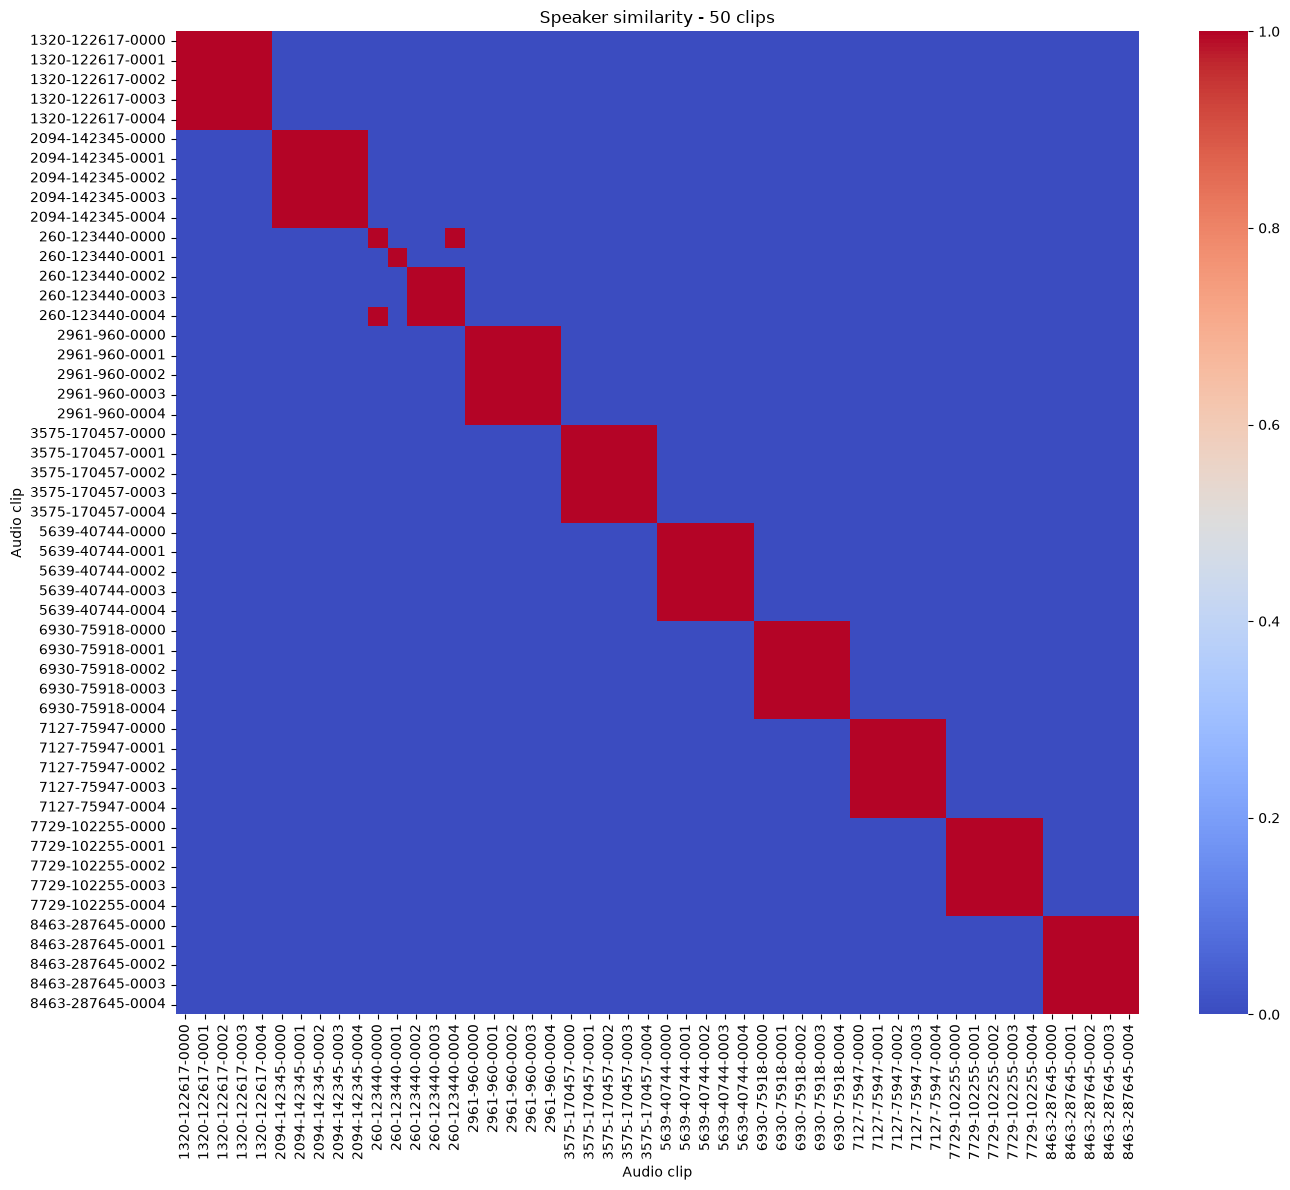

In [15]:
import matplotlib.pyplot as plt 
import seaborn as sns

plt.figure(figsize=(14,12))

sns.heatmap(
    data=similarity_df > 0.5,
    cmap='coolwarm',
)
plt.xlabel('Audio clip')
plt.ylabel('Audio clip')
plt.title('Speaker similarity - 50 clips')
plt.tight_layout()
plt.show()


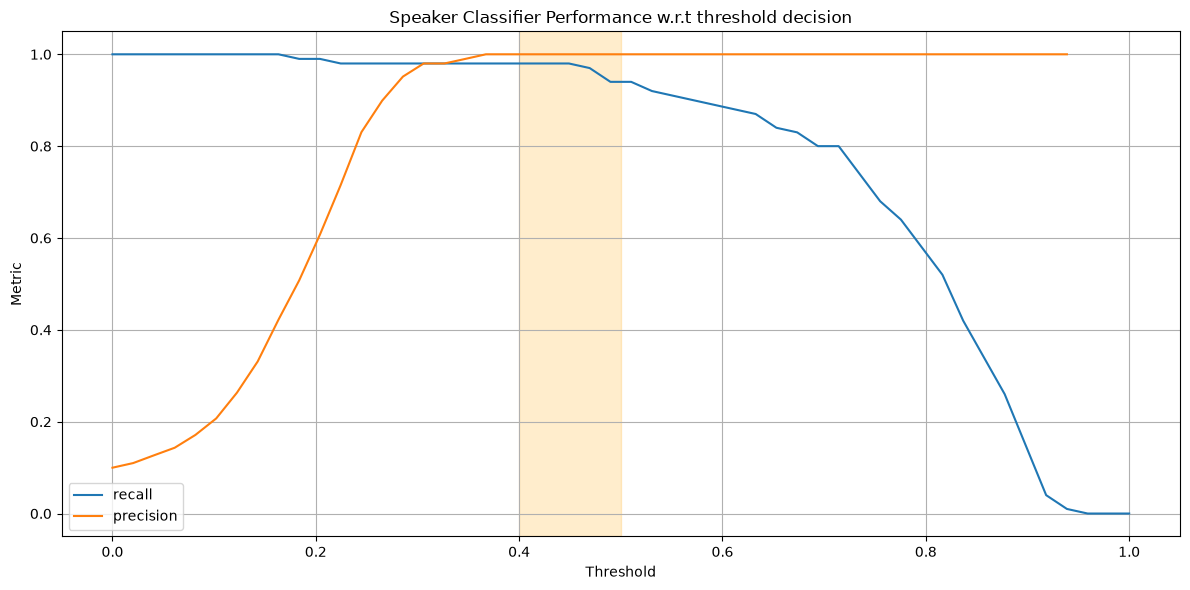

In [77]:
plt.figure(figsize=(12,6))

plt.plot(x,recalls, label= 'recall')
plt.plot(x, precisions, label = 'precision' )
plt.axvspan(0.4, 0.5, color='orange', alpha=0.2)
plt.legend()
plt.grid()
plt.xlabel('Threshold')
plt.ylabel('Metric')
plt.title('Speaker Classifier Performance w.r.t threshold decision')
plt.tight_layout()
plt.savefig('data/precision_recall_vs_threshold.png')
plt.show()


In [ ]:
# we notice that the optimal threshold is 0.4 in this case 

In [6]:
similarity_df > 0.7

,1320-122617-0000,1320-122617-0001,1320-122617-0002,1320-122617-0003,1320-122617-0004,2094-142345-0000,2094-142345-0001,2094-142345-0002,2094-142345-0003,2094-142345-0004,...,7729-102255-0000,7729-102255-0001,7729-102255-0002,7729-102255-0003,7729-102255-0004,8463-287645-0000,8463-287645-0001,8463-287645-0002,8463-287645-0003,8463-287645-0004
clip_id,,,,,,,,,,,,,,,,,,,,,
1320-122617-0000,True,True,True,True,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1320-122617-0001,True,True,True,True,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1320-122617-0002,True,True,True,True,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1320-122617-0003,True,True,True,True,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1320-122617-0004,True,True,True,True,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2094-142345-0000,False,False,False,False,False,True,True,True,True,True,...,False,False,False,False,False,False,False,False,False,False
2094-142345-0001,False,False,False,False,False,True,True,True,True,True,...,False,False,False,False,False,False,False,False,False,False
2094-142345-0002,False,False,False,False,False,True,True,True,True,True,...,False,False,False,False,False,False,False,False,False,False
2094-142345-0003,False,False,False,False,False,True,True,True,True,True,...,False,False,False,False,False,False,False,False,False,False
